Dữ liệu: X=(2000, 75), y=(2000,)
Benign: 1000, DGA: 1000
Độ dài tối đa: 75
Train: (1600, 75), Test: (400, 75)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 75, 64)         │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 256)            │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,369 (853.00 KB)

 Trainable params: 218,369 (853.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step - accuracy: 0.6506 - loss: 0.6426 - val_accuracy: 0.8475 - val_loss: 0.4358
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 164ms/step - accuracy: 0.8481 - loss: 0.3504 - val_accuracy: 0.8625 - val_loss: 0.3238
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 197ms/step - accuracy: 0.8569 - loss: 0.3204 - val_accuracy: 0.8700 - val_loss: 0.3161
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 145ms/step - accuracy: 0.8669 - loss: 0.3080 - val_accuracy: 0.8750 - val_loss: 0.3064
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 255ms/step - accuracy: 0.8725 - loss: 0.2946 - val_accuracy: 0.8650 - val_loss: 0.3235
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 225ms/step - accuracy: 0.8750 - loss: 0.2937 - val_accuracy: 0.9000 - val_loss: 0.2896
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 0.8763 - loss: 0.2848 - val_accuracy: 0.8950 - val_loss: 0.2878
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 106ms/step - accuracy: 0.8813 - loss: 0.2825 - val_accuracy: 0.

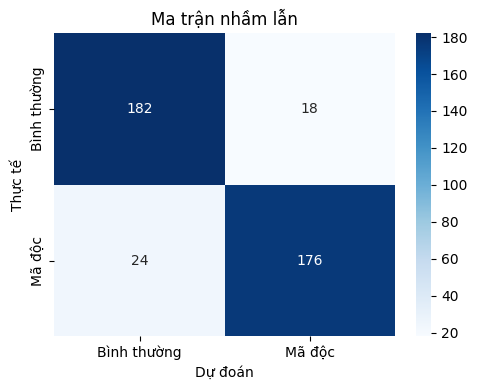

In [3]:
# ============================================================
# PHÁT HIỆN MÃ ĐỘC DGA BẰNG LSTM (FIXED VERSION)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, Input
from tensorflow.keras.callbacks import EarlyStopping

# -------------------- 1. LOAD DATA --------------------
root_folder = Path.cwd()
data = np.load(root_folder / "Dataset" / "1000_dga_dataset_binary.npz", allow_pickle=True)

X = data["X"]
y = data["y"]
char2idx = data["char2idx"].item()
max_length = int(data["max_length"])

print(f"Dữ liệu: X={X.shape}, y={y.shape}")
print(f"Benign: {sum(y==0)}, DGA: {sum(y==1)}")
print(f"Độ dài tối đa: {max_length}")

# -------------------- 2. TRAIN / TEST SPLIT --------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# -------------------- 3. MODEL (FIXED) --------------------
model = Sequential([
    Input(shape=(max_length,)),   # ⭐ FIX UNBUILT + FIX SUMMARY

    Embedding(
        input_dim=len(char2idx) + 1,
        output_dim=64
    ),

    Bidirectional(LSTM(128)),

    Dropout(0.5),

    Dense(64, activation='relu'),

    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# -------------------- 4. TRAINING --------------------
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=1
)

# -------------------- 5. EVALUATION --------------------
y_pred_prob = model.predict(X_test).flatten()
y_pred = (y_pred_prob > 0.5).astype(int)

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=["Benign", "DGA"]))

# -------------------- 6. CONFUSION MATRIX --------------------

# Ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)

# Vẽ heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Bình thường', 'Mã độc'],
    yticklabels=['Bình thường', 'Mã độc']
)

plt.title("Ma trận nhầm lẫn")
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.tight_layout()
plt.show()